In [1]:
import nflreadpy as nfl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
pbp = nfl.load_pbp([2026])

In [3]:
df = pbp.to_pandas()

## General Dataset Anlysis

In [4]:
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (20841, 372)


,play_id,game_id,old_game_id,home_team,away_team,season_type,week,posteam,posteam_type,defteam,...,out_of_bounds,home_opening_kickoff,qb_epa,xyac_epa,xyac_mean_yardage,xyac_median_yardage,xyac_success,xyac_fd,xpass,pass_oe
0,1.0,2026_01_ARI_LAC,2026091308,LAC,ARI,REG,1,None,None,None,...,0.0,0.0,-0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,39.0,2026_01_ARI_LAC,2026091308,LAC,ARI,REG,1,ARI,away,LAC,...,0.0,0.0,0.291195,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,62.0,2026_01_ARI_LAC,2026091308,LAC,ARI,REG,1,ARI,away,LAC,...,0.0,0.0,1.730269,0.402115,5.429666,3.0,1.0,1.000000,0.453482,54.651752
3,87.0,2026_01_ARI_LAC,2026091308,LAC,ARI,REG,1,ARI,away,LAC,...,0.0,0.0,-0.288451,NaN,NaN,NaN,NaN,NaN,0.402800,-40.280038
4,109.0,2026_01_ARI_LAC,2026091308,LAC,ARI,REG,1,ARI,away,LAC,...,0.0,0.0,-0.889568,0.361333,4.490768,2.0,1.0,0.998909,0.616770,38.322973


In [5]:
#Looking at different columns

df.columns.tolist()

['play_id',
 'game_id',
 'old_game_id',
 'home_team',
 'away_team',
 'season_type',
 'week',
 'posteam',
 'posteam_type',
 'defteam',
 'side_of_field',
 'yardline_100',
 'game_date',
 'quarter_seconds_remaining',
 'half_seconds_remaining',
 'game_seconds_remaining',
 'game_half',
 'quarter_end',
 'drive',
 'sp',
 'qtr',
 'down',
 'goal_to_go',
 'time',
 'yrdln',
 'ydstogo',
 'ydsnet',
 'desc',
 'play_type',
 'yards_gained',
 'shotgun',
 'no_huddle',
 'qb_dropback',
 'qb_kneel',
 'qb_spike',
 'qb_scramble',
 'pass_length',
 'pass_location',
 'air_yards',
 'yards_after_catch',
 'run_location',
 'run_gap',
 'field_goal_result',
 'kick_distance',
 'extra_point_result',
 'two_point_conv_result',
 'home_timeouts_remaining',
 'away_timeouts_remaining',
 'timeout',
 'timeout_team',
 'td_team',
 'td_player_name',
 'td_player_id',
 'posteam_timeouts_remaining',
 'defteam_timeouts_remaining',
 'total_home_score',
 'total_away_score',
 'posteam_score',
 'defteam_score',
 'score_differential',
 'po

In [6]:
#Finding the different play types and the amount of times they occured

df['play_type'].value_counts()

play_type
pass           8433
run            6225
no_play        2181
kickoff        1227
punt            897
extra_point     551
field_goal      493
qb_kneel        180
qb_spike         45
Name: count, dtype: int64

In [7]:
#Using original datafram we found the average yards gained per play by play type

df.groupby('play_type')['yards_gained'].mean()

play_type
extra_point    0.000000
field_goal     0.000000
kickoff        0.000000
no_play        0.000000
pass           6.202300
punt           0.000000
qb_kneel      -1.155556
qb_spike       0.000000
run            4.351325
Name: yards_gained, dtype: float64

## Passing Play Analysis

In [8]:
#Creating a new dataframe of just pass plays

pass_plays = df[df['play_type'] == 'pass']

In [9]:
#Finding the average passing yards per play

str(round(pass_plays['yards_gained'].mean(), 2))

'6.2'

In [10]:
#Sorting the top 10 highest yards gained passing plays

pass_plays.sort_values(by = 'yards_gained', ascending = False).head(10)

,play_id,game_id,old_game_id,home_team,away_team,season_type,week,posteam,posteam_type,defteam,...,out_of_bounds,home_opening_kickoff,qb_epa,xyac_epa,xyac_mean_yardage,xyac_median_yardage,xyac_success,xyac_fd,xpass,pass_oe
5509,503.0,2026_03_ARI_SF,2026092709,SF,ARI,REG,3,SF,home,ARI,...,0.0,0.0,7.660430,0.994348,3.805263,2.0,0.347572,0.200109,0.968367,3.163332
5173,178.0,2026_02_SEA_ARI,2026092010,ARI,SEA,REG,2,SEA,away,ARI,...,0.0,1.0,6.907721,0.825684,10.688336,5.0,1.000000,1.000000,0.600798,39.920169
1386,531.0,2026_01_GB_MIN,2026091310,MIN,GB,REG,1,GB,away,MIN,...,0.0,1.0,7.049448,0.371987,4.684528,2.0,1.000000,1.000000,0.518829,48.117059
12613,414.0,2026_05_IND_PIT,2026101105,PIT,IND,REG,5,PIT,home,IND,...,0.0,1.0,5.702825,0.782944,6.872151,6.0,0.578250,0.227173,0.511861,48.813862
4341,3614.0,2026_02_MIA_SF,2026092012,SF,MIA,REG,2,MIA,away,SF,...,0.0,0.0,7.010916,1.272485,12.779172,5.0,1.000000,1.000000,0.940648,5.935156
19083,3243.0,2026_08_ATL_TB,2026110107,TB,ATL,REG,8,ATL,away,TB,...,0.0,0.0,4.605727,0.465510,7.230537,3.0,1.000000,1.000000,0.707535,29.246527
19858,1780.0,2026_08_KC_DEN,2026110109,DEN,KC,REG,8,KC,away,DEN,...,0.0,0.0,7.018989,0.139762,3.666029,1.0,0.992024,0.951182,0.975872,2.412814
5807,3290.0,2026_03_ATL_GB,2026092400,GB,ATL,REG,3,ATL,away,GB,...,1.0,0.0,5.162955,0.612609,8.356286,4.0,1.000000,1.000000,0.724288,27.571213
4720,1147.0,2026_02_NYG_LA,2026092100,LA,NYG,REG,2,LA,home,NYG,...,0.0,0.0,5.417247,0.687332,9.222065,4.0,1.000000,1.000000,0.976204,2.379584
2617,801.0,2026_01_WAS_PHI,2026091311,PHI,WAS,REG,1,PHI,home,WAS,...,0.0,0.0,4.174296,1.081391,12.300362,7.0,1.000000,1.000000,0.463226,53.677404


In [11]:
#Total number of pass plays, incomplete and completed

len(pass_plays)

8433

In [12]:
#Only counting completed passes

len(pass_plays[pass_plays['complete_pass'] == 1])

5061

In [13]:
#Finding the amount of passing plays that resulted in a first down

len(pass_plays[pass_plays['first_down'] == 1])

2676

In [14]:
#Finding the total passing attempts/completed passes and getting the overall completion %

pass_attempts = len(pass_plays['pass_attempt'])
completed_passes = len(pass_plays[pass_plays['complete_pass'] == 1])

completion_percentage = (completed_passes / pass_attempts) * 100

print("The overall completion percentage up until the current week in the NFL is:", round(completion_percentage, 2))

The overall completion percentage up until the current week in the NFL is: 60.01


In [15]:
#Finding average yards per completed pass

round(pass_plays[pass_plays['complete_pass'] == 1]['yards_gained'].mean(), 2)

np.float64(11.02)

## Team Analysis

In [16]:
#Finding unique team abbreviations

df['posteam'].unique()

array([None, 'ARI', 'LAC', 'PIT', 'ATL', 'IND', 'BAL', 'BUF', 'HOU',
       'CHI', 'CAR', 'CLE', 'JAX', 'DAL', 'NYG', 'DEN', 'KC', 'MIN', 'GB',
       'MIA', 'LV', 'SEA', 'NE', 'DET', 'NO', 'NYJ', 'TEN', 'LA', 'SF',
       'TB', 'CIN', 'WAS', 'PHI'], dtype=object)

In [17]:
#Finding average yards gained by team

round(df.groupby('posteam')['yards_gained'].mean().sort_values(ascending = False),2)

posteam
SF     4.99
KC     4.95
BUF    4.83
CIN    4.62
DET    4.61
NE     4.61
LA     4.52
JAX    4.48
CHI    4.33
ATL    4.27
CAR    4.22
SEA    4.19
BAL    4.18
DAL    4.18
NYJ    4.15
GB     4.12
HOU    4.11
LV     4.10
NYG    4.02
PIT    4.00
MIA    3.90
WAS    3.86
CLE    3.73
TEN    3.71
NO     3.70
TB     3.69
ARI    3.67
MIN    3.64
LAC    3.55
IND    3.54
DEN    3.53
PHI    3.42
Name: yards_gained, dtype: float64

In [18]:
#Filtering to only show Kansas City

df[df['posteam'] == 'KC'].head()

,play_id,game_id,old_game_id,home_team,away_team,season_type,week,posteam,posteam_type,defteam,...,out_of_bounds,home_opening_kickoff,qb_epa,xyac_epa,xyac_mean_yardage,xyac_median_yardage,xyac_success,xyac_fd,xpass,pass_oe
1209,126.0,2026_01_DEN_KC,2026091400,KC,DEN,REG,1,KC,home,DEN,...,0.0,0.0,-0.449889,NaN,NaN,NaN,NaN,NaN,0.436777,-43.677735
1210,148.0,2026_01_DEN_KC,2026091400,KC,DEN,REG,1,KC,home,DEN,...,0.0,0.0,-0.047746,NaN,NaN,NaN,NaN,NaN,0.678747,-67.874742
1211,170.0,2026_01_DEN_KC,2026091400,KC,DEN,REG,1,KC,home,DEN,...,0.0,0.0,-1.674052,NaN,NaN,NaN,NaN,NaN,0.847737,-84.773660
1212,192.0,2026_01_DEN_KC,2026091400,KC,DEN,REG,1,KC,home,DEN,...,0.0,0.0,2.773584,NaN,NaN,NaN,NaN,NaN,0.777337,-77.733690
1213,220.0,2026_01_DEN_KC,2026091400,KC,DEN,REG,1,KC,home,DEN,...,0.0,0.0,-0.509119,0.243511,3.162037,1.0,0.998908,0.471895,0.453168,54.683167


In [19]:
#Finding just Kansas City's average passing yards gained

kc_passing = df[(df['posteam'] == 'KC') & (df['play_type'] == 'pass')]

print("Kansas City's average passing yards gained is:", round(kc_passing['yards_gained'].mean(), 2))

Kansas City's average passing yards gained is: 7.2


In [20]:
#Finding which teams attmepted the most passes sorting from highest to lowest

df.groupby('posteam')['pass_attempt'].sum().sort_values(ascending = False)

posteam
ARI    349.0
GB     327.0
LA     320.0
DAL    316.0
PIT    314.0
LV     308.0
CAR    299.0
IND    293.0
NO     289.0
CLE    286.0
CIN    281.0
NYJ    265.0
NYG    265.0
DET    264.0
HOU    264.0
TEN    263.0
DEN    263.0
CHI    259.0
NE     257.0
PHI    253.0
BAL    251.0
ATL    244.0
SEA    243.0
KC     242.0
LAC    236.0
TB     231.0
BUF    222.0
SF     219.0
WAS    218.0
MIN    216.0
JAX    215.0
MIA    206.0
Name: pass_attempt, dtype: float64

In [21]:
pass_attempts = df.groupby('posteam')['pass_attempt'].sum()

In [22]:
#Finding the completion percentage for each team and ranking them from highest to lowest

pass_attempts = df.groupby('posteam')['pass_attempt'].sum()
completed_pass = df.groupby('posteam')['complete_pass'].sum()

total_team_comp_percentage = round((completed_pass / pass_attempts) * 100, 2).sort_values(ascending = False)

total_team_comp_percentage

posteam
CIN    69.40
SF     66.67
LA     64.38
CHI    63.71
KC     63.64
DET    63.64
NO     63.32
NE     62.65
DAL    62.34
NYJ    62.26
BAL    61.35
JAX    60.93
BUF    60.81
LV     60.71
HOU    60.61
ARI    60.46
SEA    60.08
TEN    58.94
GB     58.72
CLE    58.04
MIN    56.94
WAS    56.88
DEN    56.65
IND    55.97
ATL    55.74
PIT    55.73
LAC    55.51
NYG    55.47
TB     55.41
PHI    54.55
CAR    53.85
MIA    52.43
dtype: float64

In [23]:
#Finding the top 10 teams by total passing yards

df[df['play_type'] == 'pass'].groupby('posteam')['yards_gained'].sum().sort_values(ascending = False).head(10)

posteam
GB     2170.0
LV     2123.0
LA     2071.0
CIN    2019.0
DAL    1985.0
NE     1955.0
DET    1848.0
CAR    1832.0
ARI    1790.0
HOU    1776.0
Name: yards_gained, dtype: float64

In [24]:
#Finding the top 10 teams by average yards gained per pass play

pass_plays = df[df['play_type'] == 'pass']

passing_yards = pass_plays.groupby('posteam')['yards_gained'].sum()

passing_attempts = df.groupby('posteam')['pass_attempt'].sum()

yards_per_attempt = round(passing_yards / passing_attempts, 2).sort_values(ascending = False)

yards_per_attempt.head(10)

posteam
SF     7.81
BUF    7.73
NE     7.61
JAX    7.40
KC     7.20
CIN    7.19
DET    7.00
LV     6.89
HOU    6.73
GB     6.64
dtype: float64

In [25]:
#Finding total number of passing touchdowns by team

df.groupby('posteam')['pass_touchdown'].sum().sort_values(ascending = False)

posteam
CIN    20.0
LV     19.0
JAX    17.0
GB     16.0
LA     15.0
SF     15.0
NE     15.0
DET    15.0
DAL    14.0
PIT    13.0
NO     13.0
ARI    13.0
CAR    13.0
SEA    12.0
KC     12.0
NYJ    12.0
NYG    11.0
BUF    11.0
HOU    11.0
PHI    10.0
ATL    10.0
BAL    10.0
WAS    10.0
DEN     9.0
MIN     8.0
CHI     7.0
CLE     7.0
MIA     6.0
TB      6.0
TEN     6.0
IND     5.0
LAC     5.0
Name: pass_touchdown, dtype: float64

In [26]:
#Finding total interceptions by team

df.groupby('posteam')['interception'].sum().sort_values(ascending = False)

posteam
ATL    11.0
LAC    10.0
IND     9.0
LA      8.0
SEA     8.0
NE      8.0
TB      7.0
ARI     7.0
CIN     6.0
NO      6.0
NYG     6.0
PIT     6.0
GB      6.0
PHI     5.0
CHI     5.0
LV      5.0
MIA     5.0
BUF     5.0
CAR     5.0
TEN     5.0
DAL     5.0
SF      4.0
JAX     4.0
KC      4.0
BAL     3.0
MIN     3.0
NYJ     3.0
DEN     3.0
CLE     3.0
HOU     1.0
DET     1.0
WAS     1.0
Name: interception, dtype: float64

## QB Analysis

In [27]:
#Finding the top 10 total passing yards for each QB

pass_plays = df[df['play_type'] == 'pass']

pass_plays.groupby('passer_player_name')['yards_gained'].sum().sort_values(ascending = False).head(10)

passer_player_name
J.Love        2170.0
K.Cousins     2062.0
M.Stafford    2058.0
J.Burrow      2019.0
D.Prescott    1985.0
D.Maye        1909.0
J.Goff        1848.0
B.Young       1785.0
C.Stroud      1776.0
P.Mahomes     1743.0
Name: yards_gained, dtype: float64

In [28]:
#Calculating QB Completion Percentage with more then 10 total passing attempts

pass_plays = df[df['play_type'] == 'pass']

pass_completed_qb = pass_plays.groupby('passer_player_name')['complete_pass'].sum()

pass_attempt_qb = pass_plays.groupby('passer_player_name')['pass_attempt'].sum()
pass_attempt_qb_greater_10 = pass_attempt_qb[pass_attempt_qb > 10]

completion_percent = round((pass_completed_qb / pass_attempt_qb_greater_10) * 100, 2).sort_values(ascending = False).head(10)

completion_percent

passer_player_name
G.Minshew     80.95
J.Dart        72.22
D.Lock        70.00
J.Burrow      69.40
B.Purdy       67.28
L.Jackson     66.67
M.Stafford    64.97
C.Williams    64.71
P.Mahomes     63.64
C.Keenum      63.64
dtype: float64

In [29]:
#Calculating top 10 QB interception leaders

df.groupby('passer_player_name')['interception'].sum().sort_values(ascending = False).head(10)

passer_player_name
J.Herbert     10.0
D.Jones        9.0
M.Stafford     8.0
D.Maye         8.0
S.Darnold      8.0
J.Brissett     7.0
A.Rodgers      6.0
T.Shough       6.0
J.Burrow       6.0
J.Love         6.0
Name: interception, dtype: float64

In [30]:
#Calculating top 10 QB yards per attempt (minimum 100 attempts)

pass_plays = df[df['play_type'] == 'pass']

pass_attempt_qb = pass_plays.groupby('passer_player_name')['pass_attempt'].sum()
pass_attempt_qb_greater_100 = pass_attempt_qb[pass_attempt_qb > 100]

pass_yards_gained_qb = pass_plays.groupby('passer_player_name')['yards_gained'].sum()

total_pass_per_attempt_qb = round((pass_yards_gained_qb / pass_attempt_qb_greater_100), 2).sort_values(ascending = False).head(10)

total_pass_per_attempt_qb

passer_player_name
L.Jackson     8.85
B.Purdy       7.88
J.Allen       7.73
D.Maye        7.64
T.Lawrence    7.51
P.Mahomes     7.20
J.Burrow      7.19
J.Goff        7.00
K.Cousins     6.97
C.Williams    6.90
dtype: float64

## Creating QB Stats Table

In [31]:
#Creating a QB stats table

pass_plays = df[df['play_type'] == 'pass']

qb_stats = pass_plays.groupby('passer_player_name')['pass_attempt'].sum().reset_index()

qb_stats.head()

,passer_player_name,pass_attempt
0,A.Cole,1.0
1,A.Dalton,1.0
2,A.Kaliakmanis,34.0
3,A.Richardson,3.0
4,A.Rodgers,308.0


In [32]:
#Creating a new column of passing yards to add in, using map function to map the qb in the main table with the formula output

qb_stats['passing_yards'] = qb_stats['passer_player_name'].map(pass_plays.groupby('passer_player_name')['yards_gained'].sum())

qb_stats.head()

,passer_player_name,pass_attempt,passing_yards
0,A.Cole,1.0,13.0
1,A.Dalton,1.0,0.0
2,A.Kaliakmanis,34.0,177.0
3,A.Richardson,3.0,-2.0
4,A.Rodgers,308.0,1684.0


In [33]:
#Adding in interceptions thrown by each QB

qb_stats['interceptions'] = qb_stats['passer_player_name'].map(pass_plays.groupby('passer_player_name')['interception'].sum())

qb_stats.head()

,passer_player_name,pass_attempt,passing_yards,interceptions
0,A.Cole,1.0,13.0,0.0
1,A.Dalton,1.0,0.0,1.0
2,A.Kaliakmanis,34.0,177.0,1.0
3,A.Richardson,3.0,-2.0,0.0
4,A.Rodgers,308.0,1684.0,6.0


In [34]:
#Adding completion percentage into the table

qb_stats['completions'] = qb_stats['passer_player_name'].map(pass_plays.groupby('passer_player_name')['complete_pass'].sum())

qb_stats['completion_pct'] = round((qb_stats['completions'] / qb_stats['pass_attempt']) * 100, 2)

qb_stats.head()

,passer_player_name,pass_attempt,passing_yards,interceptions,completions,completion_pct
0,A.Cole,1.0,13.0,0.0,1.0,100.00
1,A.Dalton,1.0,0.0,1.0,0.0,0.00
2,A.Kaliakmanis,34.0,177.0,1.0,15.0,44.12
3,A.Richardson,3.0,-2.0,0.0,2.0,66.67
4,A.Rodgers,308.0,1684.0,6.0,175.0,56.82


In [35]:
#Adding yards per attempt into the table

qb_stats['yards_per_attempt'] = round(qb_stats['passing_yards'] / qb_stats['pass_attempt'], 2)

qb_stats.head()

,passer_player_name,pass_attempt,passing_yards,interceptions,completions,completion_pct,yards_per_attempt
0,A.Cole,1.0,13.0,0.0,1.0,100.00,13.00
1,A.Dalton,1.0,0.0,1.0,0.0,0.00,0.00
2,A.Kaliakmanis,34.0,177.0,1.0,15.0,44.12,5.21
3,A.Richardson,3.0,-2.0,0.0,2.0,66.67,-0.67
4,A.Rodgers,308.0,1684.0,6.0,175.0,56.82,5.47


In [36]:
#Creating new column of passing touchdowns

qb_stats['passing_tds'] = qb_stats['passer_player_name'].map(pass_plays.groupby('passer_player_name')['pass_touchdown'].sum())

qb_stats.head()

,passer_player_name,pass_attempt,passing_yards,interceptions,completions,completion_pct,yards_per_attempt,passing_tds
0,A.Cole,1.0,13.0,0.0,1.0,100.00,13.00,0.0
1,A.Dalton,1.0,0.0,1.0,0.0,0.00,0.00,0.0
2,A.Kaliakmanis,34.0,177.0,1.0,15.0,44.12,5.21,1.0
3,A.Richardson,3.0,-2.0,0.0,2.0,66.67,-0.67,0.0
4,A.Rodgers,308.0,1684.0,6.0,175.0,56.82,5.47,13.0


In [37]:
#Creating TD percentage, how likely a QB is to throw a TD based on passing attempts (NOT completed passes)

qb_stats['td_percentage'] = round((qb_stats['passing_tds'] / qb_stats['pass_attempt']) * 100, 2)

qb_stats.head()

,passer_player_name,pass_attempt,passing_yards,interceptions,completions,completion_pct,yards_per_attempt,passing_tds,td_percentage
0,A.Cole,1.0,13.0,0.0,1.0,100.00,13.00,0.0,0.00
1,A.Dalton,1.0,0.0,1.0,0.0,0.00,0.00,0.0,0.00
2,A.Kaliakmanis,34.0,177.0,1.0,15.0,44.12,5.21,1.0,2.94
3,A.Richardson,3.0,-2.0,0.0,2.0,66.67,-0.67,0.0,0.00
4,A.Rodgers,308.0,1684.0,6.0,175.0,56.82,5.47,13.0,4.22


In [38]:
#Creating interception percentage based on passing attempts

qb_stats['int_percentage'] = round((qb_stats['interceptions'] / qb_stats['pass_attempt']) * 100, 2)

qb_stats.head()

,passer_player_name,pass_attempt,passing_yards,interceptions,completions,completion_pct,yards_per_attempt,passing_tds,td_percentage,int_percentage
0,A.Cole,1.0,13.0,0.0,1.0,100.00,13.00,0.0,0.00,0.00
1,A.Dalton,1.0,0.0,1.0,0.0,0.00,0.00,0.0,0.00,100.00
2,A.Kaliakmanis,34.0,177.0,1.0,15.0,44.12,5.21,1.0,2.94,2.94
3,A.Richardson,3.0,-2.0,0.0,2.0,66.67,-0.67,0.0,0.00,0.00
4,A.Rodgers,308.0,1684.0,6.0,175.0,56.82,5.47,13.0,4.22,1.95


In [39]:
#Sorting QB stats to see who has the most passing ayrds

qb_stats.sort_values(by = 'passing_yards', ascending = False).head(10)

,passer_player_name,pass_attempt,passing_yards,interceptions,completions,completion_pct,yards_per_attempt,passing_tds,td_percentage,int_percentage
36,J.Love,327.0,2170.0,6.0,192.0,58.72,6.64,16.0,4.89,1.83
41,K.Cousins,296.0,2062.0,5.0,180.0,60.81,6.97,19.0,6.42,1.69
49,M.Stafford,314.0,2058.0,8.0,204.0,64.97,6.55,15.0,4.78,2.55
29,J.Burrow,281.0,2019.0,6.0,195.0,69.40,7.19,20.0,7.12,2.14
21,D.Prescott,316.0,1985.0,5.0,197.0,62.34,6.28,14.0,4.43,1.58
20,D.Maye,250.0,1909.0,8.0,157.0,62.80,7.64,15.0,6.00,3.20
33,J.Goff,264.0,1848.0,1.0,168.0,63.64,7.00,15.0,5.68,0.38
9,B.Young,292.0,1785.0,5.0,158.0,54.11,6.11,13.0,4.45,1.71
13,C.Stroud,259.0,1776.0,1.0,160.0,61.78,6.86,11.0,4.25,0.39
52,P.Mahomes,242.0,1743.0,4.0,154.0,63.64,7.20,12.0,4.96,1.65


## Visualizing QB Data

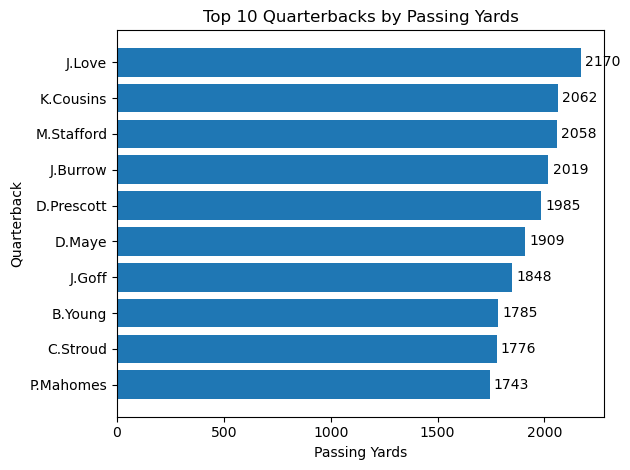

In [40]:
#Visualizing top 10 QBs by passing yards bar chart

top_10_qbs = qb_stats.sort_values(by = 'passing_yards', ascending = False).head(10)

bars = plt.barh(top_10_qbs['passer_player_name'],
         top_10_qbs['passing_yards'],
        color = 'tab:blue')

plt.title('Top 10 Quarterbacks by Passing Yards')
plt.xlabel('Passing Yards')
plt.ylabel('Quarterback')
plt.bar_label(bars, padding = 3)

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [41]:
#Want to first filter out and only show QBs with 150+ passing yards minimum

qb_yards_filtered = qb_stats[qb_stats['passing_yards'] > 150]

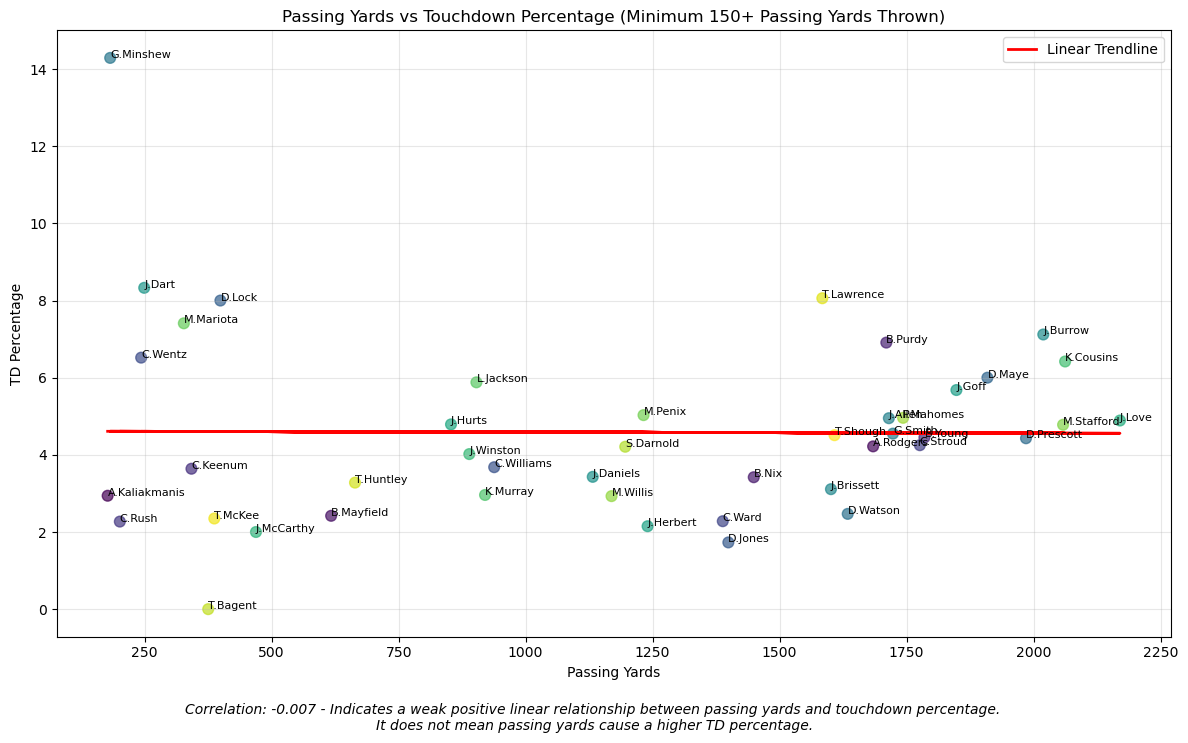

In [42]:
#Creating scatter plot to compare passing yards against touchdown percentage

#Calculating the correlation

qb_corr = round(qb_yards_filtered['passing_yards'].corr(qb_yards_filtered['td_percentage']), 3)

#Creating Trendline
x = qb_yards_filtered['passing_yards']
y = qb_yards_filtered['td_percentage']
coefficients = np.polyfit(x, y, 1)
trendline = np.poly1d(coefficients)

#Scatter Plot
plt.figure(figsize = (12, 7))
plt.scatter(qb_yards_filtered['passing_yards'], qb_yards_filtered['td_percentage'], c = range(len(qb_yards_filtered)), cmap = 'viridis', s = 60, alpha = 0.7)

#This creates the QB annotation for each circle
for index, row in qb_yards_filtered.iterrows():
    plt.annotate(
        row['passer_player_name'],
        (row['passing_yards'], row['td_percentage']), fontsize = 8)

#General Scatterplot descriptions
plt.title('Passing Yards vs Touchdown Percentage (Minimum 150+ Passing Yards Thrown)')
plt.xlabel('Passing Yards')
plt.ylabel('TD Percentage')

#This creates the trendline
plt.plot(x, trendline(x), color = 'red', linewidth = 2, label = 'Linear Trendline')

#Adding an annocation at the bottom to explain the correlation
plt.figtext(
    0.5, -0.05,
    f'Correlation: {qb_corr:.3f} - Indicates a weak positive linear relationship between passing yards and touchdown percentage. \nIt does not mean passing yards cause a higher TD percentage.',
    ha = 'center',
    fontsize = 10,
    style = 'italic')

plt.tight_layout()
plt.grid(True, alpha = 0.3)
plt.legend()
plt.show()

## QB Touchdown Percentage Analysis

In [43]:
#Creating a new Dataframe with the respected columns below and then sorting the highest td_percentages only showing top 10

top_10_td_pct = qb_yards_filtered[['passer_player_name', 'pass_attempt', 'passing_tds', 'td_percentage']]

top_10_td_pct = top_10_td_pct.sort_values(by = 'td_percentage', ascending = False).head(10)
top_10_td_pct

,passer_player_name,pass_attempt,passing_tds,td_percentage
25,G.Minshew,21.0,3.0,14.29
31,J.Dart,36.0,3.0,8.33
61,T.Lawrence,211.0,17.0,8.06
19,D.Lock,50.0,4.0,8.00
46,M.Mariota,54.0,4.0,7.41
29,J.Burrow,281.0,20.0,7.12
8,B.Purdy,217.0,15.0,6.91
15,C.Wentz,46.0,3.0,6.52
41,K.Cousins,296.0,19.0,6.42
20,D.Maye,250.0,15.0,6.00


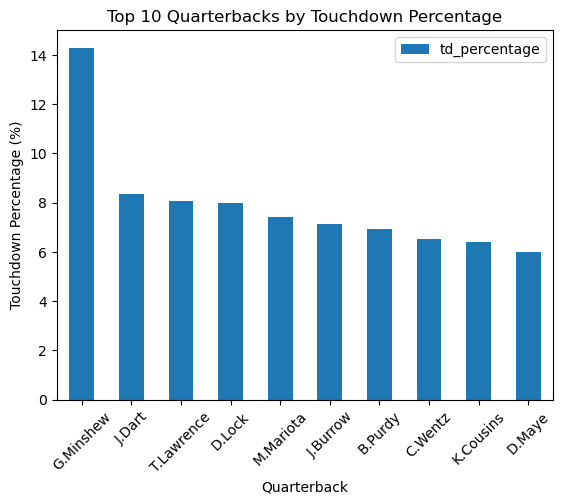

In [44]:
# Creating a bar chart to help visualize the top 10 QBs by TD Percentage

top_10_td_pct.plot(x = 'passer_player_name', y = 'td_percentage', kind = 'bar', title = 'Top 10 Quarterbacks by Touchdown Percentage')
plt.xlabel('Quarterback')
plt.ylabel('Touchdown Percentage (%)')
plt.xticks(rotation = 45)
plt.show()

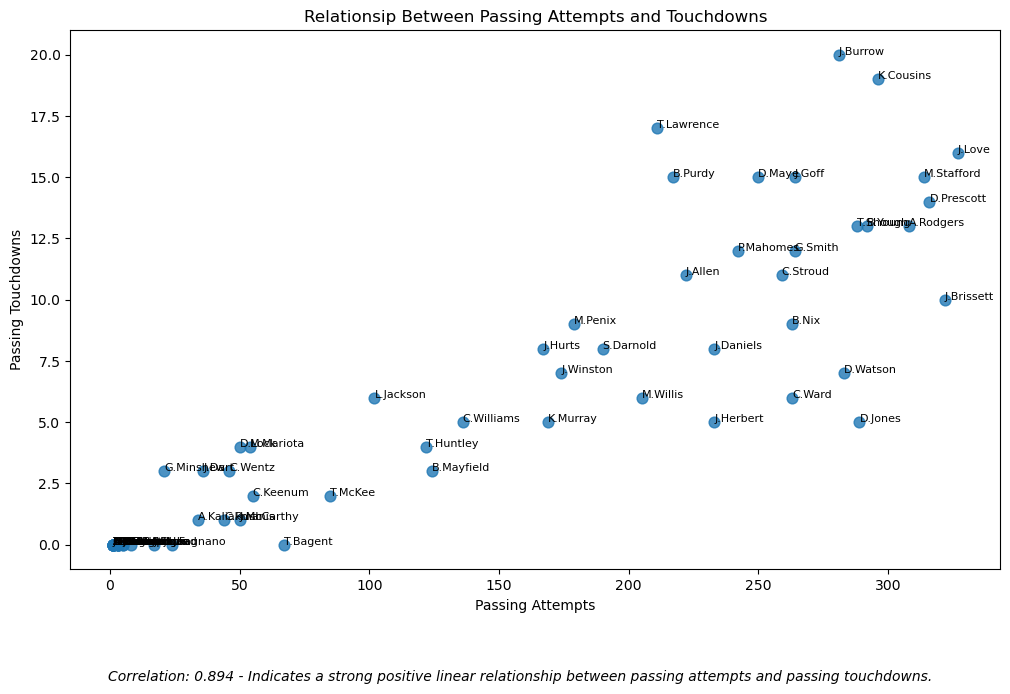

In [45]:
#Analyzing relationship between passing attempts and touchdowns

#Calcualting Correlation
qb_corr_attempts = round(qb_stats['pass_attempt'].corr(qb_stats['passing_tds']), 3)

plt.figure(figsize= (12,7))
plt.scatter(qb_stats['pass_attempt'], qb_stats['passing_tds'], s = 60, alpha = 0.8)

for index, row in qb_stats.iterrows():
    plt.annotate(
        row['passer_player_name'],
        (row['pass_attempt'], row['passing_tds']), fontsize = 8)

plt.title('Relationsip Between Passing Attempts and Touchdowns')
plt.xlabel('Passing Attempts')
plt.ylabel('Passing Touchdowns')

#Adding an annocation at the bottom to explain the correlation
plt.figtext(
    0.5, -0.05,
    f'Correlation: {qb_corr_attempts:.3f} - Indicates a strong positive linear relationship between passing attempts and passing touchdowns.',
    ha = 'center',
    fontsize = 10,
    style = 'italic')

plt.show()

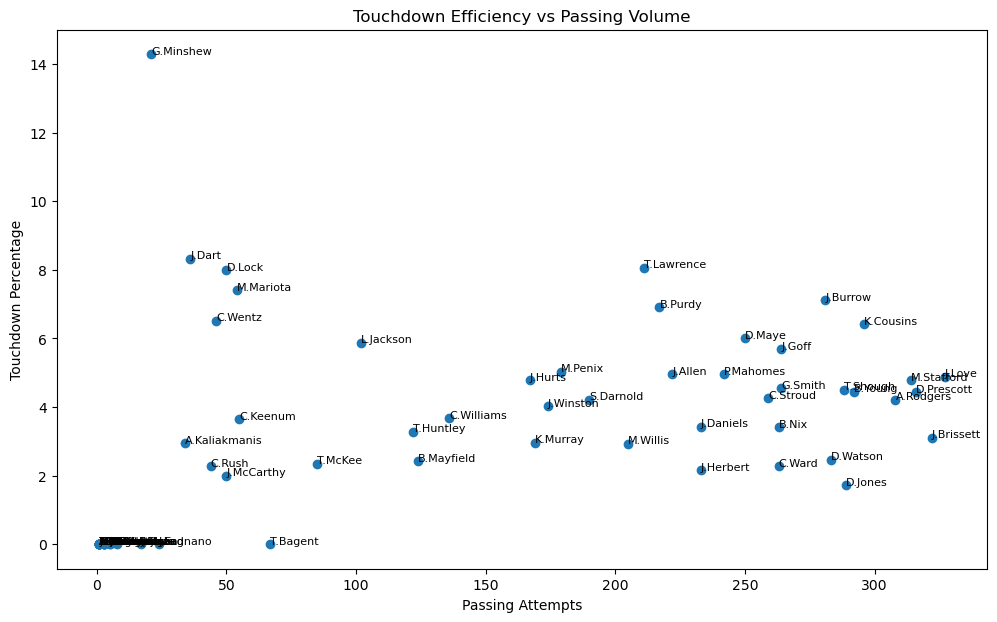

In [46]:
#Calculating Touchdown Efficiency vs Passing Volume
#we want to investigate whether quarterbacks who throw more frequently are actually more efficient at producing touchdowns

plt.figure(figsize = (12,7))
plt.scatter(qb_stats['pass_attempt'], qb_stats['td_percentage'])

#Adding annotations in

for index, row in qb_stats.iterrows():
    plt.annotate(
        row['passer_player_name'],
        (row['pass_attempt'], row['td_percentage']), fontsize = 8)

plt.title('Touchdown Efficiency vs Passing Volume')
plt.xlabel('Passing Attempts')
plt.ylabel('Touchdown Percentage')
plt.show()

In [47]:
#Calculating Correlation

correlation = np.corrcoef(qb_stats['pass_attempt'], qb_stats['td_percentage'])
correlation[0, 1]

np.float64(0.4767247800861053)

In [48]:
#Investigating Correlation

#Creating a new dataframe with only the three columns
qb_eff_sorted = qb_stats[['passer_player_name', 'pass_attempt', 'td_percentage']]

#Sorting the dataframe by pass_attempt in descending order
qb_eff_sorted.sort_values(by = 'pass_attempt', ascending = False).head(10)

#Can see that throwing it more doesnt really mean there more efficient percent wise

,passer_player_name,pass_attempt,td_percentage
36,J.Love,327.0,4.89
28,J.Brissett,322.0,3.11
21,D.Prescott,316.0,4.43
49,M.Stafford,314.0,4.78
4,A.Rodgers,308.0,4.22
41,K.Cousins,296.0,6.42
9,B.Young,292.0,4.45
18,D.Jones,289.0,1.73
63,T.Shough,288.0,4.51
22,D.Watson,283.0,2.47


In [49]:
#Sorting the dataframe by pass_attempt in descending order
qb_eff_sorted.sort_values(by = 'pass_attempt', ascending = True).head(10)

#We can see without filtering out the Quarterbacks with low passing attempts it skews our data and correlation

,passer_player_name,pass_attempt,td_percentage
0,A.Cole,1.0,0.0
59,T.Harris,1.0,0.0
51,Mi.Wilson,1.0,0.0
48,M.Rudolph,1.0,0.0
42,K.Kroeger,1.0,0.0
38,J.Smith-Njigba,1.0,0.0
23,E.Chism,1.0,0.0
17,D.Brown,1.0,0.0
10,C.Johnston,1.0,0.0
65,Z.Flowers,1.0,0.0


In [50]:
#Filtering out the low volume Quarterbacks

qb_min_attempts = qb_stats[qb_stats['pass_attempt'] >= 100]
qb_min_attempts.head()

,passer_player_name,pass_attempt,passing_yards,interceptions,completions,completion_pct,yards_per_attempt,passing_tds,td_percentage,int_percentage
4,A.Rodgers,308.0,1684.0,6.0,175.0,56.82,5.47,13.0,4.22,1.95
6,B.Mayfield,124.0,617.0,2.0,68.0,54.84,4.98,3.0,2.42,1.61
7,B.Nix,263.0,1449.0,3.0,149.0,56.65,5.51,9.0,3.42,1.14
8,B.Purdy,217.0,1710.0,4.0,146.0,67.28,7.88,15.0,6.91,1.84
9,B.Young,292.0,1785.0,5.0,158.0,54.11,6.11,13.0,4.45,1.71


In [51]:
#Finding the shape of the new filtered dataframe to find how many QBs remain (33)

qb_min_attempts.shape

(33, 10)

In [65]:
correlation_filtered = np.corrcoef(qb_min_attempts['pass_attempt'], qb_min_attempts['td_percentage'])
correlation_value = correlation_filtered[0,1]

#Relationship we observed in the full dataset becomes almost nonexistent when we restrict the analysis to quarterbacks with at least 100 attempts.
#Suggests the low-volume quarterbacks may have been influencing the original correlation

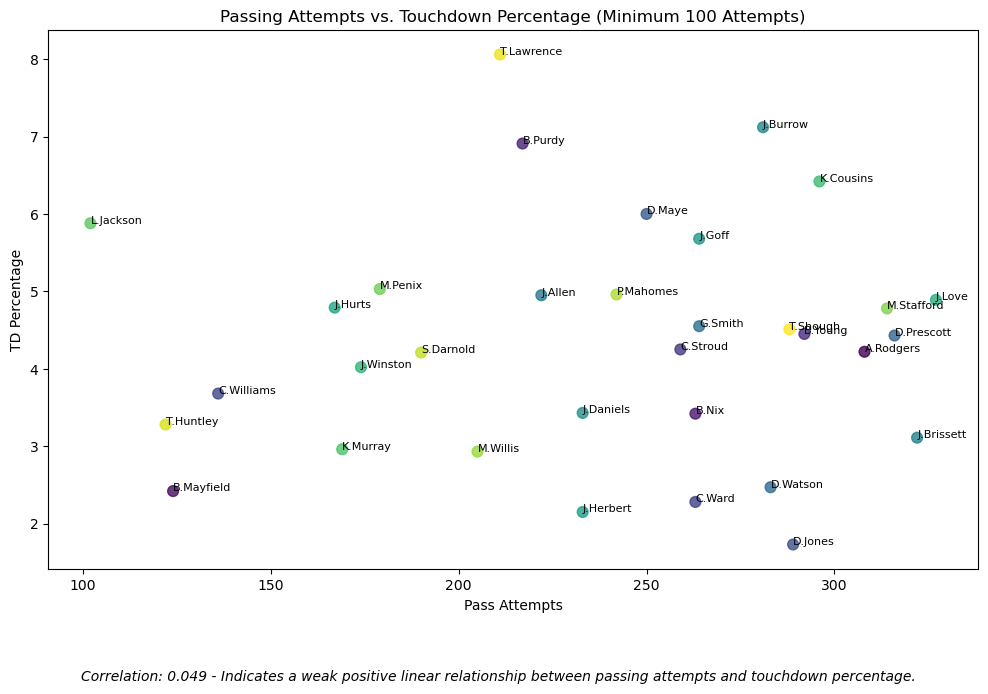

In [72]:
#Lets visualize the above correlation to get a better understanding of there being no correlation

plt.figure(figsize = (12,7))
plt.scatter(qb_min_attempts['pass_attempt'], qb_min_attempts['td_percentage'], c = range(len(qb_min_attempts)), cmap = 'viridis', s = 60, alpha = 0.8)

for index, row in qb_min_attempts.iterrows():
    plt.annotate(
        row['passer_player_name'],
        (row['pass_attempt'], row['td_percentage']), fontsize = 8)
    
plt.figtext(
    0.5, -0.05,
    f'Correlation: {correlation_value:.3f} - Indicates a weak positive linear relationship between passing attempts and touchdown percentage.',
    ha = 'center',
    fontsize = 10,
    style = 'italic')

plt.title('Passing Attempts vs. Touchdown Percentage (Minimum 100 Attempts)')
plt.xlabel('Pass Attempts')
plt.ylabel('TD Percentage')
plt.show()